# Fraud Detection: Diversity Features (reproduction)

A teammate looked at the ~800 fraud cases the model missed on the validation split. They look like normal clients on most measures, but they have a **more varied meter setup**: more distinct counter codes, reading remarks and tariffs. From this, 12 new per-client features were built. The teammate reports validation ROC-AUC **0.860 → 0.880** (mean of 3 seeds).

Here we **reproduce** this and check it:
- **27 base features**: the 30 features of feature set v2 minus `coef_not1_share`, `has_backward`, `backward_count` (reported as never used by the model).
- **39 features**: 27 base + the 12 new ones from `build_diversity_features()` in [features.py](features.py).
- Two settings: the **v2 settings** from notebook 12 (used by the teammate, `models/lightgbm_v2_best_params.json`) and the **notebook 09 settings** (`models/lightgbm_best_params.json`), which the team chose for the final model on 2026-10-22 (see [protocol.md](protocol.md)).
- No tuning. Fit on the training split, score on the validation split, seeds 42, 1 and 2, mean reported. Then 5-fold CV on the training split as a second check.
- The new features are built from the cleaned tables and saved as new tables `X_*_v3.csv` (the v2 tables stay unchanged). The test set only gets features, it is not scored.
- At the end, the 39 features are **tuned** once with the same random search as notebooks 09 and 12, and the final model is checked on the validation split (team decision: the final model uses the 39 features).

**Caveats:**
- The settings were tuned on the old features, and the F1-best threshold is chosen on the validation split, so precision, recall and F1 are slightly optimistic. ROC-AUC does not depend on a threshold.
- `n_remarque` and `remarque_8_share` use `reading_remarque`. The team decided on 2026-10-20 not to use `reading_remarque` as a model feature, so adopting these features would change that decision.

The notebook shows tables and one chart: the confusion matrices of the final model.

In [1]:
# reload features.py when it changes, so a running kernel does not use an old version
%load_ext autoreload
%autoreload 2

# libraries for data handling, the model, cross-validation and the metrics
import json
import numpy as np
import pandas as pd
from pathlib import Path
from lightgbm import LGBMClassifier
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, randint, uniform
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate

from features import build_diversity_features

pd.set_option("display.max_columns", 40)
FEATURE_DIR = Path("data/features")
CLEAN_DIR = Path("data/clean")
MODEL_DIR = Path("models")
SEEDS = [42, 1, 2]

## 1. Load feature set v2 and the two settings

In [2]:
# read one feature table from data/features, with client_id as the index
def load(name):
    return pd.read_csv(FEATURE_DIR / f"{name}.csv", index_col="client_id")

v2_columns = json.loads((MODEL_DIR / "selected_features.json").read_text())["features"]
dropped = ["coef_not1_share", "has_backward", "backward_count"]
base = [c for c in v2_columns if c not in dropped]

X_train, X_valid, X_test = load("X_train_v2"), load("X_valid_v2"), load("X_test_v2")
y_train, y_valid = load("y_train")["target"], load("y_valid")["target"]

settings = {
    "v2 settings (notebook 12)": json.loads((MODEL_DIR / "lightgbm_v2_best_params.json").read_text()),
    "notebook 09 settings (final model)": json.loads((MODEL_DIR / "lightgbm_best_params.json").read_text()),
}
print(len(v2_columns), "v2 features ->", len(base), "base features")

30 v2 features -> 27 base features


### Check: are the 3 dropped columns really unused?

`shap` is not installed in the project, so we use LightGBM's own importance: **split** = how often a feature is used in a split, **gain** = how much those splits improved the model. A feature that is never used has 0 for both.

In [3]:
# one model with the v2 settings on all 30 v2 features
check = LGBMClassifier(**settings["v2 settings (notebook 12)"], n_jobs=-1, verbose=-1).fit(X_train[v2_columns], y_train)
importance = pd.DataFrame({
    "split": check.booster_.feature_importance("split"),
    "gain share (%)": 100 * check.booster_.feature_importance("gain") / check.booster_.feature_importance("gain").sum(),
}, index=v2_columns)
importance.loc[dropped].round(3)

,split,gain share (%)
coef_not1_share,0,0.000
has_backward,1,0.001
backward_count,20,0.022


## 2. Build the 12 new features (in memory)

| Group | Column | Rule (per client, own bills only) |
|---|---|---|
| **Diversity** | `n_codes` | number of distinct `counter_code` |
| | `n_remarque` | number of distinct `reading_remarque` (after cleaning: codes 6 to 9, rare codes = 0) |
| | `n_tarif` | number of distinct `tarif_type` |
| | `remarque_8_share` | share of bills with `reading_remarque` = 8 |
| **Consumption shape** | `cons_cv` | std / (mean + 1) of consumption; 0 for a single bill (as `cons_std`) |
| | `level2_3_share` | (level 2 + level 3) / (total consumption + 1) |
| | `level4_share` | level 4 / (total consumption + 1) |
| | `cons_p90_over_median` | (90th percentile + 1) / (median + 1) |
| **Time activity** | `share_last_2y` | share of bills in the 730 days before the last bill |
| | `bills_in_2016_17` | number of bills in 2016 or 2017 |
| | `days_since_last_bill` | days from the last bill to 2020-01-01 |
| | `inv_per_date` | distinct (date, meter type) pairs / distinct bill dates |

In [4]:
# the cleaned tables (read only)
client_train = pd.read_csv(CLEAN_DIR / "client_train_clean.csv")
invoice_train = pd.read_csv(CLEAN_DIR / "invoice_train_clean.csv", parse_dates=["invoice_date"], low_memory=False)
client_test = pd.read_csv(CLEAN_DIR / "client_test_clean.csv")
invoice_test = pd.read_csv(CLEAN_DIR / "invoice_test_clean.csv", parse_dates=["invoice_date"], low_memory=False)

new_train = build_diversity_features(client_train, invoice_train)
new_test = build_diversity_features(client_test, invoice_test)
new_columns = list(new_train.columns)

# join to the v2 tables, client by client (nothing is written to data/)
X_train, X_valid, X_test = X_train.join(new_train), X_valid.join(new_train), X_test.join(new_test)
all_39 = base + new_columns

# checks: same columns everywhere, one row per client, all test clients, no id or target
assert list(X_train.columns) == list(X_valid.columns) == list(X_test.columns)
assert X_train.index.is_unique and X_valid.index.is_unique and len(X_test) == 58069
assert not {"client_id", "target"} & set(all_39)
print(len(new_columns), "new features,", len(all_39), "in total")
X_train[new_columns].describe().T.round(3)

12 new features, 39 in total


,count,mean,std,min,25%,50%,75%,max
n_codes,108394.0,1.541,0.600,1.000,1.000,1.000,2.000,6.000
n_remarque,108394.0,2.456,0.782,1.000,2.000,3.000,3.000,4.000
n_tarif,108394.0,1.513,0.573,1.000,1.000,1.000,2.000,6.000
remarque_8_share,108394.0,0.163,0.159,0.000,0.000,0.147,0.250,1.000
cons_cv,108394.0,0.920,0.560,0.000,0.587,0.862,1.158,8.005
level2_3_share,108394.0,0.101,0.161,0.000,0.000,0.014,0.147,1.000
level4_share,108394.0,0.020,0.089,0.000,0.000,0.000,0.000,0.994
cons_p90_over_median,108394.0,31.783,438.448,1.000,1.626,2.289,3.951,66837.800
share_last_2y,108394.0,0.387,0.328,0.005,0.147,0.222,0.556,1.000
bills_in_2016_17,108394.0,5.879,4.903,0.000,1.000,6.000,10.000,72.000


In [5]:
# save the extended tables as feature set v3 (the v2 files stay unchanged)
for name, table in {"X_train_v3": X_train, "X_valid_v3": X_valid, "X_test_v3": X_test}.items():
    table.to_csv(FEATURE_DIR / f"{name}.csv")
(MODEL_DIR / "selected_features_v3.json").write_text(json.dumps({"features": all_39}, indent=2))
print("saved X_train_v3, X_valid_v3, X_test_v3 and models/selected_features_v3.json")

saved X_train_v3, X_valid_v3, X_test_v3 and models/selected_features_v3.json


## 3. Helper: train on the training split, score the validation split

In [6]:
def evaluate(params, columns, seed):
    # fit with the given settings and seed, predict the validation clients
    model = LGBMClassifier(**{**params, "random_state": seed}, n_jobs=-1, verbose=-1)
    model.fit(X_train[columns], y_train)
    proba = model.predict_proba(X_valid[columns])[:, 1]

    # F1-best threshold (chosen on validation, so an upper bound)
    precision, recall, thresholds = precision_recall_curve(y_valid, proba)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    best = f1.argmax()
    flagged = proba >= thresholds[best]
    fraud = (y_valid == 1).values
    return {
        "ROC-AUC": roc_auc_score(y_valid, proba),
        "PR-AUC": average_precision_score(y_valid, proba),
        "precision": precision[best], "recall": recall[best], "F1": f1[best],
        "caught": int((flagged & fraud).sum()),
        "missed": int((~flagged & fraud).sum()),
        "false alarms": int((flagged & ~fraud).sum()),
    }


def mean_over_seeds(params, columns):
    # mean of the 3 seeds
    return pd.DataFrame([evaluate(params, columns, s) for s in SEEDS]).mean()

## 4. 27 base vs 39 features (validation split, mean of 3 seeds)

The teammate's numbers (v2 settings): 27 base ROC-AUC 0.860, PR-AUC 0.326, precision 0.324, recall 0.454, F1 0.378; 39 features ROC-AUC 0.880, PR-AUC 0.370, precision 0.369, recall 0.503, F1 0.425.

In [7]:
rows = {}
for setting, params in settings.items():
    for label, columns in [("27 base", base), ("39 features", all_39)]:
        rows[(setting, label)] = mean_over_seeds(params, columns)
main = pd.DataFrame(rows).T

# difference to the teammate's ROC-AUC (v2 settings only)
expected = {("v2 settings (notebook 12)", "27 base"): 0.860, ("v2 settings (notebook 12)", "39 features"): 0.880}
main["expected ROC-AUC"] = [expected.get(i, np.nan) for i in main.index]
main["difference"] = main["ROC-AUC"] - main["expected ROC-AUC"]
main.round(3)

ROC-AUC  PR-AUC  precision  \
v2 settings (notebook 12)          27 base        0.859   0.326      0.324   
                                   39 features    0.881   0.371      0.367   
notebook 09 settings (final model) 27 base        0.858   0.316      0.333   
                                   39 features    0.879   0.362      0.344   

                                                recall     F1   caught  \
v2 settings (notebook 12)          27 base       0.454  0.378  687.000   
                                   39 features   0.504  0.424  762.667   
notebook 09 settings (final model) 27 base       0.433  0.376  655.667   
                                   39 features   0.532  0.418  805.667   

                                                 missed  false alarms  \
v2 settings (notebook 12)          27 base      826.000      1431.667   
                                   39 features  750.333      1325.000   
notebook 09 settings (final model) 27 base      857.333      1315.333   
                                   39 features  707.333      1536.000   

                                                expected ROC-AUC  difference  
v2 settings (notebook 12)          27 base                  0.86      -0.001  
                                   39 features              0.88       0.001  
notebook 09 settings (final model) 27 base                   NaN         NaN  
                                   39 features               NaN         NaN

In [8]:
# gain of the 39 features over the 27 base, per setting
gain = {}
for setting in settings:
    gain[setting] = main.loc[(setting, "39 features")] - main.loc[(setting, "27 base")]
pd.DataFrame(gain).T[["ROC-AUC", "PR-AUC", "F1", "caught", "missed", "false alarms"]].round(3)

,ROC-AUC,PR-AUC,F1,caught,missed,false alarms
v2 settings (notebook 12),0.021,0.045,0.045,75.667,-75.667,-106.667
notebook 09 settings (final model),0.020,0.046,0.042,150.000,-150.000,220.667


## 5. Which group brings the gain? (v2 settings, mean of 3 seeds)

In [9]:
groups = {
    "diversity": ["n_codes", "n_remarque", "n_tarif", "remarque_8_share"],
    "consumption shape": ["cons_cv", "level2_3_share", "level4_share", "cons_p90_over_median"],
    "time activity": ["share_last_2y", "bills_in_2016_17", "days_since_last_bill", "inv_per_date"],
}
assert sorted(c for g in groups.values() for c in g) == sorted(new_columns)

v2 = settings["v2 settings (notebook 12)"]
group_rows = {"27 base": main.loc[("v2 settings (notebook 12)", "27 base")]}
for name, cols in groups.items():
    group_rows[f"27 + {name}"] = mean_over_seeds(v2, base + cols)
group_rows["39 features"] = main.loc[("v2 settings (notebook 12)", "39 features")]
pd.DataFrame(group_rows).T[["ROC-AUC", "PR-AUC", "F1", "caught", "false alarms"]].round(3)

,ROC-AUC,PR-AUC,F1,caught,false alarms
27 base,0.859,0.326,0.378,687.000,1431.667
27 + diversity,0.877,0.367,0.420,710.333,1155.333
27 + consumption shape,0.858,0.324,0.381,674.000,1351.667
27 + time activity,0.863,0.331,0.383,674.333,1334.000
39 features,0.881,0.371,0.424,762.667,1325.000


## 6. Do we need all 39? (top 5 and top 10 by gain importance, v2 settings)

In [10]:
# rank the 39 features by gain in one v2 model (seed 42)
ranker = LGBMClassifier(**v2, n_jobs=-1, verbose=-1).fit(X_train[all_39], y_train)
ranking = pd.Series(ranker.booster_.feature_importance("gain"), index=all_39).sort_values(ascending=False)
print("top 10:", list(ranking.index[:10]))

topk = {f"top {k}": mean_over_seeds(v2, list(ranking.index[:k])) for k in (5, 10)}
topk["all 39"] = main.loc[("v2 settings (notebook 12)", "39 features")]
pd.DataFrame(topk).T[["ROC-AUC", "PR-AUC", "F1"]].round(3)

top 10: ['n_counters', 'days_since_last_bill', 'n_codes', 'region', 'consommation_level_1_sum', 'max_change_gaz', 'client_age_years', 'history_years', 'cons_std_gaz', 'gap_max_days']


,ROC-AUC,PR-AUC,F1
top 5,0.849,0.276,0.349
top 10,0.863,0.301,0.362
all 39,0.881,0.371,0.424


## 7. Second check: 5-fold cross-validation on the training split

The same folds as in notebooks 08 to 12. If the gain is real, the 39 features should win in (almost) every fold, not only on the one validation split.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = {}
for setting, params in settings.items():
    folds = {}
    for label, columns in [("27 base", base), ("39 features", all_39)]:
        result = cross_validate(LGBMClassifier(**params, n_jobs=-1, verbose=-1), X_train[columns], y_train,
                                cv=cv, scoring=["roc_auc", "average_precision"])
        folds[label] = result["test_roc_auc"]
        cv_rows[(setting, label)] = {"CV ROC-AUC": result["test_roc_auc"].mean(),
                                     "CV ROC-AUC std": result["test_roc_auc"].std(),
                                     "CV PR-AUC": result["test_average_precision"].mean()}
    cv_rows[(setting, "39 features")]["folds won"] = int((folds["39 features"] > folds["27 base"]).sum())
pd.DataFrame(cv_rows).T.round(4)

CV ROC-AUC  CV ROC-AUC std  \
v2 settings (notebook 12)          27 base          0.8480          0.0061   
                                   39 features      0.8717          0.0058   
notebook 09 settings (final model) 27 base          0.8479          0.0061   
                                   39 features      0.8707          0.0053   

                                                CV PR-AUC  folds won  
v2 settings (notebook 12)          27 base         0.3125        NaN  
                                   39 features     0.3459        5.0  
notebook 09 settings (final model) 27 base         0.3051        NaN  
                                   39 features     0.3406        5.0

## 8. Hyperparameter tuning on the 39 features

The team decided to use the 39 features for the final model. The v2 settings were tuned on the old 30 features, so we tune once more, with exactly the same random search as notebooks 09 and 12: 30 combinations × 5 folds, the same 8 ranges, the same folds, scored with ROC-AUC, the class weight fixed.

**Rule (set before the search):** the tuned settings replace the v2 settings only if they improve the mean CV ROC-AUC by **more than 0.005** and are better in **at least 4 of 5 folds**. Otherwise the v2 settings stay.

In [12]:
v2 = settings["v2 settings (notebook 12)"]

# reference: the v2 settings on the 39 features, score of every fold
ref = cross_validate(LGBMClassifier(**v2, n_jobs=-1, verbose=-1), X_train[all_39], y_train, cv=cv,
                     scoring=["roc_auc", "average_precision"], return_train_score=True)
ref_folds = ref["test_roc_auc"]
print(f"v2 settings, 39 features: CV ROC-AUC {ref_folds.mean():.4f} (± {ref_folds.std():.4f})")

# the same ranges as in notebooks 09 and 12
param_distributions = {
    "n_estimators": randint(100, 1001),
    "learning_rate": uniform(0.01, 0.14),        # 0.01 to 0.15
    "num_leaves": randint(15, 128),
    "max_depth": [-1, 4, 6, 8],
    "min_child_samples": randint(20, 301),
    "subsample": uniform(0.6, 0.4),              # 0.6 to 1.0
    "colsample_bytree": uniform(0.5, 0.5),       # 0.5 to 1.0
    "reg_lambda": loguniform(1e-3, 10),
}
search = RandomizedSearchCV(
    LGBMClassifier(class_weight="balanced", subsample_freq=1, n_jobs=-1, random_state=42, verbose=-1),
    param_distributions,
    n_iter=30,
    scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
    refit="roc_auc",
    cv=cv,
    return_train_score=True,
    random_state=42,
    verbose=1,
)
# fit on the training split only; the validation split is not touched here
search.fit(X_train[all_39], y_train)
print(f"best CV ROC-AUC of the search: {search.best_score_:.4f}")

v2 settings, 39 features: CV ROC-AUC 0.8717 (± 0.0058)
Fitting 5 folds for each of 30 candidates, totalling 150 fits


best CV ROC-AUC of the search: 0.8717


In [13]:
# the 5 best combinations: is the top stable, or one lucky draw?
results = pd.DataFrame(search.cv_results_)
results["gap"] = results["mean_train_roc_auc"] - results["mean_test_roc_auc"]
columns = ["mean_test_roc_auc", "std_test_roc_auc", "mean_test_pr_auc", "gap"] + [c for c in results.columns if c.startswith("param_")]
results.sort_values("mean_test_roc_auc", ascending=False)[columns].head(5).round(4)

,mean_test_roc_auc,std_test_roc_auc,mean_test_pr_auc,gap,param_colsample_bytree,param_learning_rate,param_max_depth,param_min_child_samples,param_n_estimators,param_num_leaves,param_reg_lambda,param_subsample
19,0.8717,0.0058,0.3459,0.0987,0.6622,0.0271,-1,250,289,111,0.0123,0.8591
28,0.8707,0.0053,0.3406,0.0606,0.8676,0.0393,6,118,362,30,1.8573,0.8221
4,0.8693,0.0056,0.3347,0.0759,0.8926,0.0380,6,263,931,17,2.7527,0.8721
26,0.8683,0.0061,0.3280,0.0643,0.9177,0.0549,4,278,759,73,0.0076,0.8845
23,0.8679,0.0048,0.3256,0.0526,0.9883,0.0675,6,243,324,15,0.0091,0.6580


In [14]:
# compare the best combination with the v2 settings, fold by fold
best = results.loc[search.best_index_]
tuned_folds = np.array([best[f"split{k}_test_roc_auc"] for k in range(5)])
gain = tuned_folds.mean() - ref_folds.mean()
wins = int((tuned_folds > ref_folds).sum())
tuned_wins = gain > 0.005 and wins >= 4

tuning_table = pd.DataFrame({
    "v2 settings": {"CV ROC-AUC": ref_folds.mean(), "CV ROC-AUC std": ref_folds.std(),
                    "CV PR-AUC": ref["test_average_precision"].mean(),
                    "gap": ref["train_roc_auc"].mean() - ref_folds.mean()},
    "tuned on 39 features": {"CV ROC-AUC": tuned_folds.mean(), "CV ROC-AUC std": tuned_folds.std(),
                             "CV PR-AUC": best["mean_test_pr_auc"], "gap": best["gap"]},
}).T
print(f"gain {gain:+.4f}, better in {wins} of 5 folds ->", "tuned settings win" if tuned_wins else "v2 settings stay")
tuning_table.round(4)

gain +0.0000, better in 0 of 5 folds -> v2 settings stay


,CV ROC-AUC,CV ROC-AUC std,CV PR-AUC,gap
v2 settings,0.8717,0.0058,0.3459,0.0987
tuned on 39 features,0.8717,0.0058,0.3459,0.0987


In [15]:
# the settings of the final model: the winner of the rule above
def plain(value):
    # numpy numbers -> plain Python numbers, so they can be saved as JSON
    return value.item() if isinstance(value, np.generic) else value

tuned_params = {k: plain(v) for k, v in search.best_params_.items()}
tuned_params.update({"class_weight": "balanced", "subsample_freq": 1, "random_state": 42})
final_params = tuned_params if tuned_wins else v2
source = "tuned on the 39 features (notebook 13)" if tuned_wins else "v2 settings (notebook 12)"

(MODEL_DIR / "lightgbm_final_params.json").write_text(json.dumps({"settings": final_params, "source": source}, indent=2))
print("final settings:", source)
final_params

final settings: v2 settings (notebook 12)


{'colsample_bytree': 0.662172510502637,
 'learning_rate': 0.027092313658094273,
 'max_depth': -1,
 'min_child_samples': 250,
 'n_estimators': 289,
 'num_leaves': 111,
 'reg_lambda': 0.012261087663689309,
 'subsample': 0.8590760482165449,
 'class_weight': 'balanced',
 'subsample_freq': 1,
 'random_state': 42}

## 9. The final model on the validation split

The final model (39 features, the settings chosen above), fitted on the training split and scored on the validation clients: all metrics as the mean of 3 seeds, then the confusion matrices for seed 42 at two cut-offs:
- **F1-best threshold**: the cut-off with the best F1 on validation (an upper bound),
- **top 10% flagged**: STEG inspects the 10% of clients with the highest score (2,710 visits), as in notebooks 10 and 11.

In [16]:
# all metrics of the final model, per seed and as the mean
final_scores = pd.DataFrame([evaluate(final_params, all_39, s) for s in SEEDS], index=[f"seed {s}" for s in SEEDS])
final_scores.loc["mean"] = final_scores.mean()
final_scores.round(3)

,ROC-AUC,PR-AUC,precision,recall,F1,caught,missed,false alarms
seed 42,0.881,0.370,0.345,0.543,0.422,822.000,691.000,1564.0
seed 1,0.880,0.368,0.388,0.462,0.422,699.000,814.000,1102.0
seed 2,0.881,0.374,0.369,0.507,0.427,767.000,746.000,1309.0
mean,0.881,0.371,0.367,0.504,0.424,762.667,750.333,1325.0


,caught fraud,missed fraud,false alarms,correct no-fraud,recall,precision
F1-best threshold (0.71),822.0,691.0,1564.0,24022.0,0.543,0.345
top 10% flagged,864.0,649.0,1846.0,23740.0,0.571,0.319


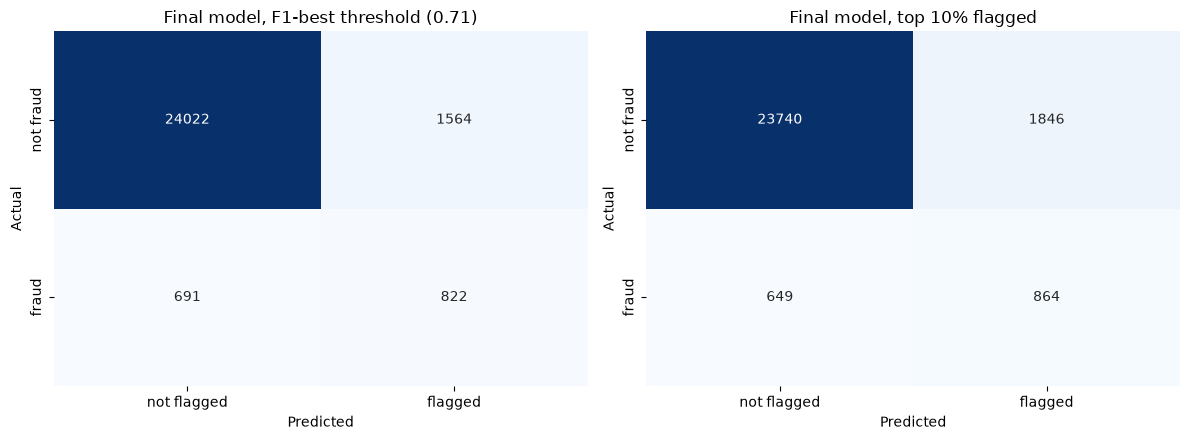

In [17]:
# one final model (seed 42) for the confusion matrices
final_model = LGBMClassifier(**{**final_params, "random_state": 42}, n_jobs=-1, verbose=-1).fit(X_train[all_39], y_train)
proba = final_model.predict_proba(X_valid[all_39])[:, 1]

precision, recall, thresholds = precision_recall_curve(y_valid, proba)
f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
cut_offs = {
    f"F1-best threshold ({thresholds[f1.argmax()]:.2f})": proba >= thresholds[f1.argmax()],
    "top 10% flagged": proba >= np.quantile(proba, 0.9),
}

matrices, rows = {}, {}
for name, flagged in cut_offs.items():
    matrices[name] = confusion_matrix(y_valid, flagged.astype(int))
    (tn, fp), (fn, tp) = matrices[name]
    rows[name] = {"caught fraud": tp, "missed fraud": fn, "false alarms": fp, "correct no-fraud": tn,
                  "recall": tp / (tp + fn), "precision": tp / (tp + fp)}
display(pd.DataFrame(rows).T.round(3))

# both confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, cm) in zip(axes, matrices.items()):
    sns.heatmap(cm, annot=True, fmt="g", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["not flagged", "flagged"], yticklabels=["not fraud", "fraud"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"Final model, {name}")
plt.tight_layout()
plt.show()

## Result

**Reproduced.** With the v2 settings, 27 base → 39 features gives validation ROC-AUC **0.859 → 0.881** (teammate: 0.860 → 0.880, difference ≤ 0.001). PR-AUC 0.326 → 0.371, F1 0.378 → 0.424 (mean of 3 seeds).

| Validation, mean of 3 seeds | ROC-AUC | PR-AUC | Precision | Recall | F1 | Caught | Missed | False alarms |
|---|---|---|---|---|---|---|---|---|
| v2 settings, 27 base | 0.859 | 0.326 | 0.324 | 0.454 | 0.378 | 687 | 826 | 1,432 |
| v2 settings, **39 features** | **0.881** | **0.371** | 0.367 | 0.504 | **0.424** | 763 | 750 | 1,325 |
| notebook 09 settings, 27 base | 0.858 | 0.316 | 0.333 | 0.433 | 0.376 | 656 | 857 | 1,315 |
| notebook 09 settings, **39 features** | **0.879** | **0.362** | 0.344 | 0.532 | **0.418** | 806 | 707 | 1,536 |

**The gain is real:**
- In 5-fold CV on the training split, the 39 features win in **5 of 5 folds** with both settings: CV ROC-AUC 0.848 → **0.872** (v2) and 0.848 → **0.871** (notebook 09). The gain (+0.023) is about 4 times the spread between the folds.
- It also holds for the **notebook 09 settings** (our final model): +0.020 ROC-AUC on validation, so it does not depend on the re-tuned settings.

**Where the gain comes from:**
- The **diversity group** (`n_codes`, `n_remarque`, `n_tarif`, `remarque_8_share`) brings most of it on its own: ROC-AUC 0.877, F1 0.420. Consumption shape (0.858) and time activity (0.863) add little alone.
- With the v2 settings the 39 features catch about **76 more fraud cases** and give about **107 fewer false alarms** (out of 1,513 fraud cases). With the notebook 09 settings they catch 150 more, but give 221 more false alarms at their F1-best threshold. The F1-best threshold sits at a different place for each setting, so these counts move a lot. ROC-AUC and PR-AUC are the fair comparison.
- **Keep all 39**: top 5 gives F1 0.349, top 10 gives 0.362 (the teammate found 0.346 and 0.407; the top-10 list differs because we rank by LightGBM gain, not SHAP).

**Checks and caveats:**
- The 3 dropped columns are **almost** unused, not completely: `coef_not1_share` 0 splits, `has_backward` 1, `backward_count` 20, together 0.02% of the gain. Dropping them is fine.
- **`days_since_last_bill` is the 2nd most important of all 39 features.** Clients whose last bill is more than 5 years old (16% of the clients) are almost never fraud (0.7% vs about 6.5%). Inactive accounts are probably rarely inspected, so they are rarely *labelled* fraud. This is the same kind of effect as `n_counters`: it helps the Zindi score (the test set has the same pattern, 16% inactive), but for STEG it mostly says "do not inspect closed accounts".
- `n_remarque` and `remarque_8_share` use `reading_remarque`, which the team decided on 2026-10-20 **not** to use as a model feature. Adopting this set changes that decision.
- The settings were tuned on the old features, and the threshold for precision, recall and F1 is chosen on validation, so those three are slightly optimistic. ROC-AUC does not depend on a threshold.
- The new columns are saved as new tables `X_*_v3.csv`; the v2 tables are unchanged. The test set only got features and was not scored.

**Tuning on the 39 features (section 8):** the best combination of the random search is exactly the v2 settings (the search draws the same 30 combinations as in notebook 12), so the gain is 0.000 and the **v2 settings stay**. The top 5 combinations lie between 0.868 and 0.872: the settings matter little, the features matter a lot.

**Final model (team decision 2026-10-22): LightGBM, 39 features, v2 settings** (`models/lightgbm_final_params.json`, feature list `models/selected_features_v3.json`).
- Validation, mean of 3 seeds: ROC-AUC **0.881**, PR-AUC 0.371, precision 0.367, recall 0.504, F1 0.424.
- Confusion matrix (seed 42) at the F1-best threshold (0.71): 822 fraud cases caught, 691 missed, 1,564 false alarms.
- In the inspection scenario (top 10% flagged, 2,710 visits): **864 of 1,513 fraud cases caught (57%)**, hit rate 32%. The first model (notebook 10) caught 517 (34%).

The final model is trained on all labelled clients in [14_final-model-submission.ipynb](14_final-model-submission.ipynb).